# Main project: regularized MovieLens factorization

ALS, SGD and Adam share a degree-scaled objective at each penalty. All methods use the same fit / validation / official test split. The initial overfitting result is preserved, and the validation extension records every candidate. Final-test reuse and the limited three-seed scope are explicit.

See [theory](../docs/theory.md), [protocol](../docs/protocol.md) and [limitations](../docs/model_cards.md).

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
ROOT=Path.cwd()
if ROOT.name=='notebooks': ROOT=ROOT.parent
sys.path.insert(0,str(ROOT/'src'))
def read(path): return json.loads((ROOT/path).read_text())
def figure(name): display(Image(filename=str(ROOT/'assets/figures'/f'{name}.png')))


## An ALS block is ridge regression

In [2]:
neighbors=np.array([[1.,0.],[0.,1.],[1.,1.]])
design=np.column_stack([np.ones(3),neighbors]);target=np.array([1.,2.,3.])
penalty=np.array([.03,.1,.1])*3
coef=np.linalg.solve(design.T@design+np.diag(penalty),design.T@target)
assert np.linalg.norm(design.T@(design@coef-target)+penalty*coef)<1e-12
print("Bias and factor block coefficients",coef)

Bias and factor block coefficients [0.81929904 0.4824761  1.25170687]


## Every selected model and seed

In [3]:
fits=pd.read_csv(ROOT/"docs/recommendation_fits.csv")
assert len(fits)==30
fits[fits.protocol=="recommendation"].groupby("method").test_rmse.agg(["mean","std","min","max"])

,mean,std,min,max
method,,,,
adam,0.937330,0.000573,0.936864,0.937970
als,0.944489,0.000772,0.943612,0.945066
bias_only,0.958161,0.000000,0.958161,0.958161
global_mean,1.153673,0.000000,1.153673,1.153673
sgd,0.933696,0.000435,0.933206,0.934037


## Optimization versus generalization

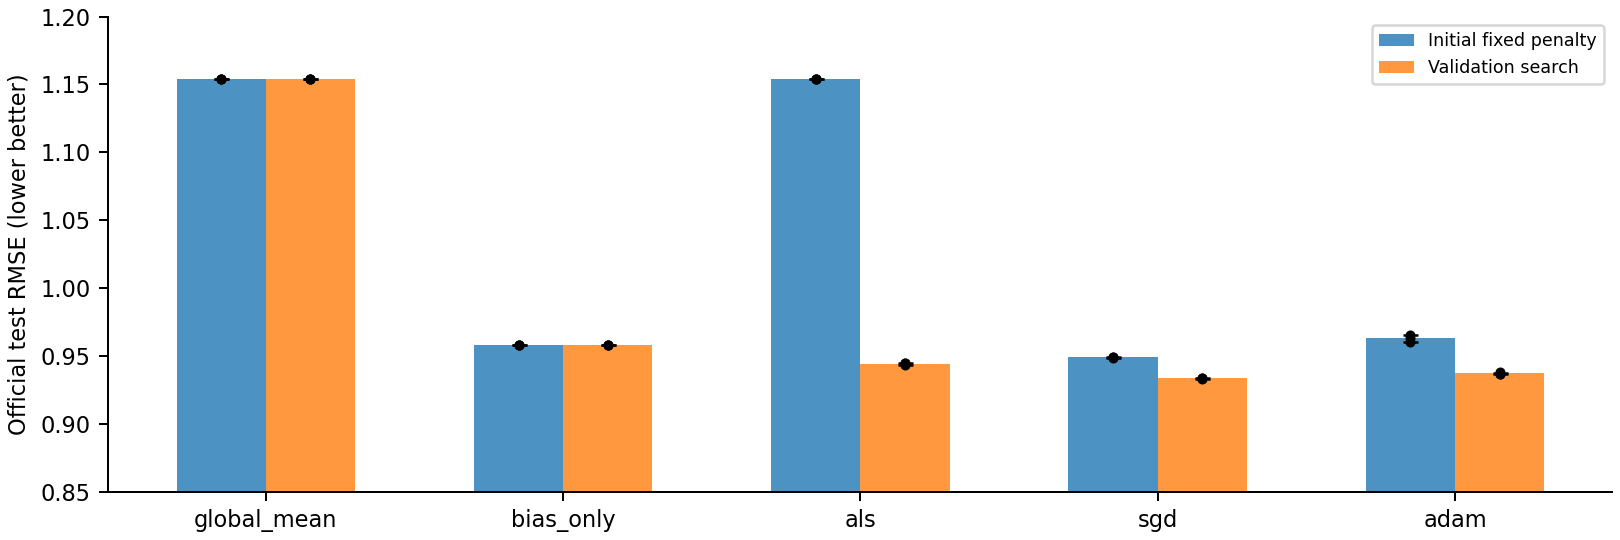

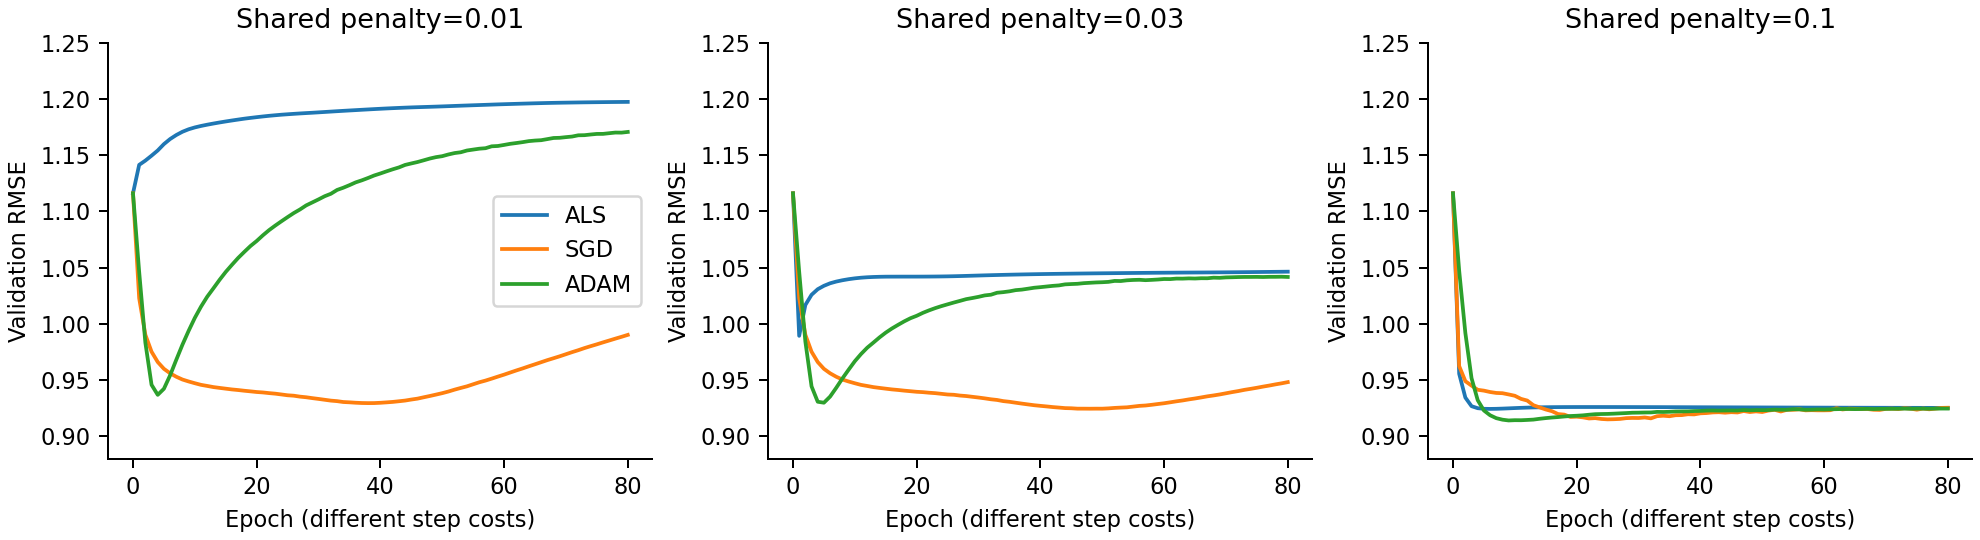

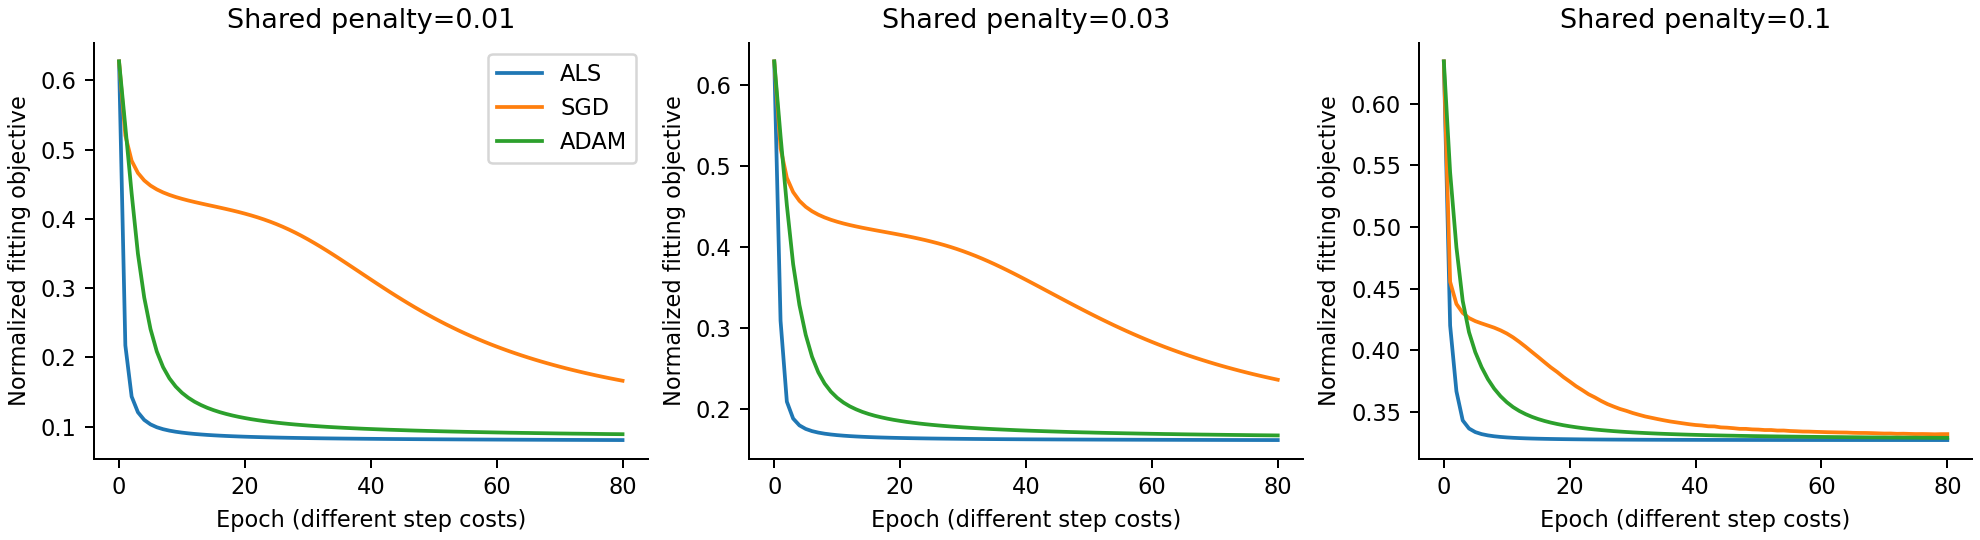

In [4]:
figure("recommendation_comparison")
figure("recommendation_matched_penalties")
figure("recommendation_optimization")

## Fresh checkpoint evidence

In [5]:
audit=read("docs/checkpoint_audit.json")
assert audit["status"]=="passed" and audit["selected_models"]==30
pd.DataFrame(audit["rows"])[["family","method","seed","test_rmse","gradient_infinity_norm"]].head(10)

,family,method,seed,test_rmse,gradient_infinity_norm
0,recommendation_fixed,global_mean,0,1.153673,1.222406e-02
1,recommendation_fixed,bias_only,0,0.958161,1.097733e-17
2,recommendation_fixed,als,0,1.153729,1.222883e-02
3,recommendation_fixed,sgd,0,0.948545,1.017595e-03
4,recommendation_fixed,adam,0,0.960547,6.267733e-04
5,recommendation_fixed,global_mean,1,1.153673,1.222406e-02
6,recommendation_fixed,bias_only,1,0.958161,1.097733e-17
7,recommendation_fixed,als,1,1.153735,1.222832e-02
8,recommendation_fixed,sgd,1,0.949568,7.361785e-04
9,recommendation_fixed,adam,1,0.963361,5.246131e-04


Full training / search commands and cache provenance are in [reproduction](../docs/reproduction.md). This notebook inspects actually completed evidence and small analytical checks; opening it does not launch the full fitting campaign.